In [1]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus
 

In [2]:
function H_Guo_dna(
        onsight_c1::Array{Array},
        onsight_c2::Array{Array},
        thopping::Array{Float64}, 
        lambda::Array{Float64},
        )
    N = length(onsight_c1[1])* 4
    onsight_e = [onsight_c1; onsight_c2]
    
    Mtrx = zeros(Float64, N,N)
    for i in 1:4:N # i = number of site n bloc
        i_steps = Integer((i+3)/4)
        Mtrx[i+2, i] = lambda[i_steps] 
        Mtrx[i, i+2] = lambda[i_steps]
        Mtrx[i+3, i+ 1] = lambda[i_steps] 
        Mtrx[i+ 1, i+3] = lambda[i_steps]
        
        for j in 1:1:4 # j = indexing  inside the bloc
        
        #diagonaleinträge
        Mtrx[(i+ j -1), (i+ j - 1)] = onsight_e[j][i_steps]
        
            if i<N-4
                #rechte hopping matrix
                Mtrx[(i +3 +j), (j +i-1)] = thopping[j]  
                #untere hoping matrix
                Mtrx[(j +i -1), (i+3 + j)] = thopping[j]
            end   
        end
    end
    return Matrix(Mtrx)
end 


H_Guo_dna (generic function with 1 method)

In [53]:
function sigma_ort(phi::Float64, theta::Float64)
    sig_x = Matrix([0 1; 1 0])
    sig_y = Matrix([0 -1im; 1im 0 ])
    sig_z = Matrix([1 0; 0 -1])
    return sig_x * sin(phi)*sin(theta) - sig_y* cos(phi)*sin(theta) + sig_z* cos(theta)
end
function sites_to_angle(N::Integer)# number of sites per helical turn
    Radius = 0.7* 10^(-9)
    delta_phi = pi* 2/N
    l_a = Radius/N
    return [delta_phi l_a]
end   
    
function H_Guo_so(
        onsight_c1::Array{Array},
        onsight_c2::Array{Array},
        sites_lap::Integer, 
        theta::Float64
        )
    N = length(onsight_c1[1])* 4
    Mtrx = zeros(Complex{Float64}, N,N)  
    
    # ? natürliche Einheiten oder SI???
    #h_quer = 1
   # R = 0.7e-9
    #dV_dr_von_R = 1
    #m = 1
    #c =1
    alpha = 1
    l_a = sites_to_angle(sites_lap)[2]
    t_so = 1#-alpha/(4*l_a)
    
    delta_phi = sites_to_angle(sites_lap)[1]
    
    # i = position of site n in full matrix, i_steps =  number of site n
    for i in 1:4:N 
        i_steps = Integer((i+3)/4)
        if i<N-4
            for z in 0:2:2 
                # für z  = 0 git j = 1 und z = 2 ist j = 2 
                if z ==0
                    #rechte hopping matrix
                    #* ist dies die h.c. seite oder die unteren matrizen?
                    sig_n_und_npl1 = 1im* (sigma_ort( i_steps*delta_phi, theta) .+ sigma_ort(( i_steps -1 ) *delta_phi, theta) )
                   #adresses a 2x2 block matrix
                    Mtrx[(i+z):(i+z+1), (i+4+z):(i+5+z)] = t_so*sig_n_und_npl1'
                    
                    #untere hopping matrix -> ohne compl conj?! 
                   Mtrx[(i+z+4):(i+z+5), (i+z):(i+1+z)] = t_so*(sig_n_und_npl1 )
                   
                end
                if z == 2
                    #plus pi in both sigma functions. As pi is half a circle adding this to phi results being on the other helical chain
                    sig_n_und_npl1 = 1im* (sigma_ort( i_steps*delta_phi + pi, theta) .+ sigma_ort(( i_steps -1 ) *delta_phi + pi, theta))
                    Mtrx[(i+z):(i+z+1), (i+4+z):(i+5+z)] = t_so*sig_n_und_npl1'
                    Mtrx[(i+z+4):(i+z+5), (i+z):(i+1+z)] = t_so*sig_n_und_npl1 
                end
            end
        end   
    end
    return Matrix(Mtrx)
end 

H_Guo_so (generic function with 1 method)

[3.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 3.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0]

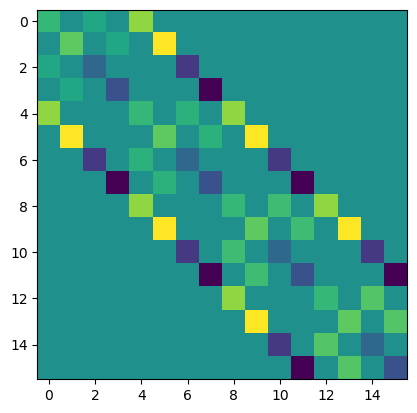

PyObject <matplotlib.image.AxesImage object at 0x7fdab5e207c0>

In [59]:
#just some tests with adressing bloc matrices
matri = zeros(Float64, 10, 10) 
matri[1:2, 1:2] .= 3
show( Matrix(matri))

# def of onsight energies
n = 4 # number of sites
onsight_chain1 =Array[ ones(n)* 1., ones(n)* 1.5] # Array[[range(0.2, 1., length =n )]; [range(0.3, 1.1, length = n)]]  # spin up; spin down
onsight_chain2 = Array[ ones(n)* (-1.), ones(n)*(-1.5)] #Array[[range(0.4, 1.2, length = n)]; [range(.5, 1.3, length = n)]]
t_hopping= Array([2. 3. -2. -3.])
#same length as n sites = length of bsp. up c1 energies
lambda = Array(range(0.6, 1.4, length = n))


H = H_Guo_dna(onsight_chain1, onsight_chain2, t_hopping, lambda)
plt.imshow(H)

In [54]:
N_test = 12#pi*5/3
theta_test = pi/2 #0.66# in rad, helix angle

sig = 1im *(sigma_ort((2*pi)/N_test, theta_test) .+ sigma_ort((4*pi)/N_test, theta_test))
print(sig, "                                                                                                ")
# Create a heatmap plot for the magnitude

Hso_test = H_Guo_so(onsight_chain1 , onsight_chain2, N_test, theta_test )
print(Hso_test[9, 1:16], "                                                                                        ")
print(Hso_test[10, 1:16])
Hso_test == Hso_test'
magnitude_matrix = abs.(Hso_test)
plt.imshow(magnitude_matrix)

Complex{Float64}[0.0 + 1.2246467991473532e-16im -1.3660254037844388 + 1.3660254037844386im; 1.3660254037844388 + 1.3660254037844386im 0.0 - 1.2246467991473532e-16im]                                                                                                Complex{Float64}[0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 1.2246467991473532e-16im, -1.3660254037844388 + 1.3660254037844386im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 - 1.2246467991473532e-16im, 0.5000000000000002 - 1.8660254037844386im, 0.0 + 0.0im, 0.0 + 0.0im]                                                                                        Complex{Float64}[0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 1.3660254037844388 + 1.3660254037844386im, 0.0 - 1.2246467991473532e-16im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, 0.0 + 0.0im, -0.5000000000000002 - 1.8660254037844386im, 0.0 + 1.2246467991473532e-16im, 0.0 + 0.0im, 0.0 + 0.0im]

true

In [6]:
function Base.show(io::IO, ::MIME"text/plain", A::AbstractArray{T}) where T
    for i in 1:size(A, 1)
        for j in 1:size(A, 2)
            print(io, ' ', A[i, j])
        end
        println(io)
    end
end

# Display the array with custom formatting
#Base.show()


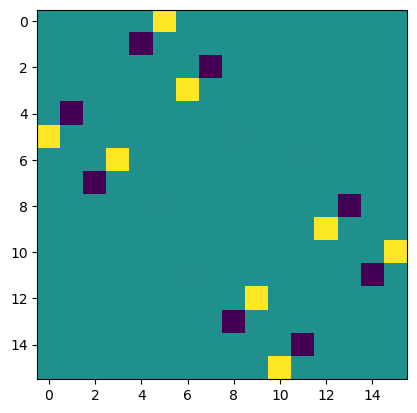

PyObject <matplotlib.image.AxesImage object at 0x7fdab1c614c0>

In [61]:

onsight_chain1 =Array[ ones(n)* 0., ones(n)* 0.] # Array[[range(0.2, 1., length =n )]; [range(0.3, 1.1, length = n)]]  # spin up; spin down
onsight_chain2 = Array[ ones(n)* (0.), ones(n)*(0)] #Array[[range(0.4, 1.2, length = n)]; [range(.5, 1.3, length = n)]]
t_hopping= Array([0. 0. 0. 0.])
#same length as n sites = length of bsp. up c1 energies
lambda = zeros(n)
H =  H_Guo_dna(onsight_chain1, onsight_chain2, t_hopping, lambda)
H_dna_compl= H .+ 0*1im

N = 6
theta = 0.66# in rad, helix angle
Hso = H_Guo_so(onsight_chain1 , onsight_chain2, N, theta )
H_all  = Hso + H_dna_compl
plt.imshow(real.(H_all))

In [43]:
function G_und_trans(energy::Float64,
        eta::Float64,
        Hamiltonian::Array{Complex{Float64}},
        gammas::Array{Complex{Float64}}
    )
    dim = size(Hamiltonian)[1]
    Matrix_I_e = (energy + eta*1im ) * Matrix(I, dim,dim)

    gamma_l = zeros(Complex{Float64}, dim,dim)
    gamma_l[1, 1] = gammas[1]
    gamma_l[2,2] = gammas[1]
    # as spin up and spin down sttate of first site are couled to lead? analogue for last of course
    #?!
    gamma_r = zeros(Complex{Float64}, dim,dim)
    gamma_r[end, end] = gammas[2]
    gamma_r[end-1, end-1] = gammas[2]
    
    matrix_self = -1im *(gamma_l+ gamma_r)/ 2 
    G_ret =  inv(Matrix_I_e - matrix_self - Hamiltonian)
    G_adv = adjoint(G_ret)
    final_Matrix = gamma_l* G_adv * gamma_r * G_ret
    return real.(tr(final_Matrix))
end 
function trans_plot(
        Hamiltonian::Array{Complex{Float64}},
        gammas::Array{Complex{Float64}},
        emin::Float64, 
        emax::Float64, 
        pdf_name::String)
    
    E_list = Array(range(emin, emax, length = 2000))
    eta = 10^(-7)
    transm_H = [G_und_trans(E,eta, H_all, gammas) for E in E_list]
    plt.figure()
    plt.plot(
        E_list, transm_H,    #mit f. normalerweise komponentenweise
        label = "transmission",
        linewidth = 2 
        )
    plt.legend()
    #plt.ylim( 0, 0.02)
    plt.title("Transmission H1 (degenerate energies for spin up and down) (n=5) at zero temp")
    plt.xlabel( "Energy in MeV")
    plt.ylabel( "Transmission coefficient")
    plt.grid("true")
    plt.savefig(pdf_name)
    plt.show()
    ei1, vec1 = eigen(H_all)
    print(ei1)
    return 
end

trans_plot (generic function with 2 methods)

Complex{Float64}[-2.8506690968901274 + 0.12960505911708115im, -2.7634153313931247 - 0.13216446088099032im, -1.5546555513878164 - 0.8509836060837922im, -1.554427597777542 + 0.8334492944524772im, -1.055952066672987 + 0.8178400681676191im, -1.0263009490947406 - 0.8156289227418532im, 0.35152596339171 + 0.09032899593514992im, 0.41961534287265334 - 0.08711779766525438im, 1.0583150141165873 - 0.11232355034188735im, 1.1359289718207541 + 0.12737463417345296im, 2.5203506804929776 + 0.7770981806575679im, 2.5240870965278197 - 0.7779050898489754im, 2.960939794435833 + 0.7997954185753573im, 2.967891650988615 - 0.7831222625106814im, 4.377922094642451 - 0.14636558248745413im, 4.488843983926929 + 0.13011962148218478im]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


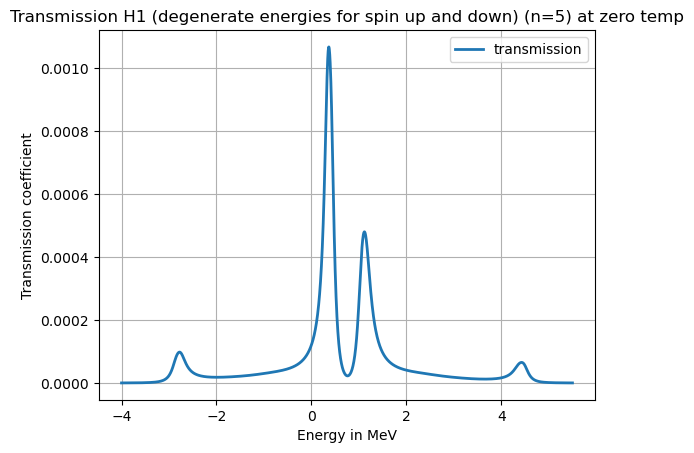

In [44]:
emin, emax = -4., 5.5
gammas = Array([(.01 + 0.0*1im) (.01+ 0.0*1im)])
trans_plot(H_all, gammas, emin, emax, "transmission_guo.pdf")

In [48]:
function integral_f(x_data::Array{Float64}, H::Array{Complex{Float64}}, 
        eta::Float64, gammas::Array{Complex{Float64}})
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        y_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

integral_f (generic function with 2 methods)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


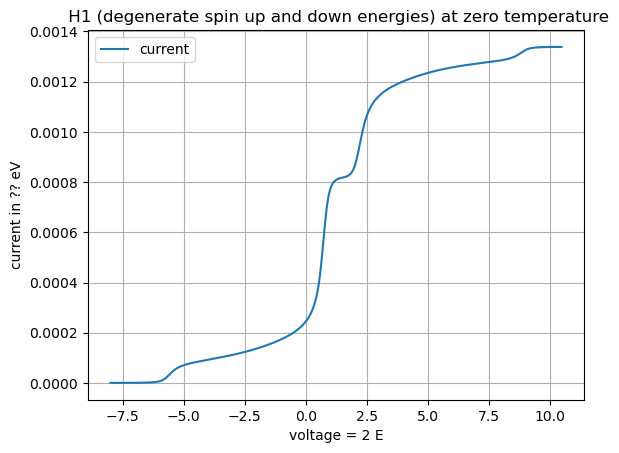

In [50]:
u_list= Array(range(-8.,10.5, length = 1000))
plt.figure( )
integral_f(u_list, H_all,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( " H1 (degenerate spin up and down energies) at zero temperature")
plt.savefig("current_H_guo.pdf")
plt.show()
